# 03 · Evaluation & model selection

Produced by `python -m ml.src.evaluate --experiment <id>` (temperature and confidence threshold fitted on **validation**; test evaluated once) and `python -m ml.src.select_model`.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'ml' / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
DATA_DIR = os.environ.get('WASTEWISE_DATA_DIR', str(ROOT / 'ml/datasets/processed'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 160)

In [2]:
from IPython.display import Image as Img, Markdown
display(Markdown(Path('ml/reports/model_comparison.md').read_text()))

# Model comparison

Selection rule: highest validation macro-F1; ties within 0.5 pp broken by lower CPU latency.
Test metrics are reported for information only and were not used for selection.

| experiment | architecture | params_m | size_mb | epochs | train_minutes | val_acc | val_f1_macro | test_acc | test_precision_macro | test_recall_macro | test_f1_macro | test_f1_weighted | test_roc_auc | hazardous_recall | e_waste_recall | threshold | coverage | acc_on_accepted | ood_rejection | latency_ms_cpu | selected |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| exp01_custom_cnn | custom_cnn | 1.96 | 7.86 | 12 | 46.6 | 0.5256 | 0.4951 | 0.5527 | 0.5342 | 0.5362 | 0.5184 | 0.5508 | 0.8555 | 0.3953 | 0.7665 | 0.87 | 0.0393 | 0.9268 | 0.9917 | 20.3 | False |
| exp02_mobilenet_v3_large | mobilenet_v3_large | 3.48 | 14.13 | 15 | 47.6 | 0.9151 | 0.9049 | 0.9234 | 0.9121 | 0.929 | 0.9192 | 0.9234 | 0.9935 | 0.9767 | 0.982 | 0.59 | 0.9464 | 0.9464 | 0.3567 | 18.1 | True |
| exp03_efficientnet_b0 | efficientnet_b0 | 4.68 | 19.02 | 10 | 52.3 | 0.9142 | 0.9078 | 0.9071 | 0.8911 | 0.9146 | 0.9 | 0.9071 | 0.9904 | 0.9767 | 0.976 | 0.59 | 0.9377 | 0.9336 | 0.3367 | 30.1 | False |


In [3]:
from ml.src.taxonomy import CATEGORIES
evals = {p.parent.name: json.load(open(p)) for p in sorted(Path('ml/reports').glob('*/evaluation.json'))}
for k, e in evals.items():
    print(k); display(pd.DataFrame(e['test']['per_class']).T.loc[list(CATEGORIES)].round(3))

exp01_custom_cnn


,precision,recall,f1-score,support
organic,0.575,0.673,0.620,165.0
paper_cardboard,0.565,0.726,0.635,168.0
plastic,0.651,0.321,0.430,168.0
metal,0.490,0.461,0.475,165.0
glass,0.515,0.411,0.457,168.0
e_waste,0.766,0.766,0.766,167.0
hazardous,0.177,0.395,0.245,43.0


exp02_mobilenet_v3_large


,precision,recall,f1-score,support
organic,0.962,0.921,0.941,165.0
paper_cardboard,0.936,0.952,0.944,168.0
plastic,0.925,0.875,0.899,168.0
metal,0.874,0.885,0.880,165.0
glass,0.916,0.911,0.913,168.0
e_waste,0.965,0.982,0.973,167.0
hazardous,0.808,0.977,0.884,43.0


exp03_efficientnet_b0


,precision,recall,f1-score,support
organic,0.908,0.952,0.929,165.0
paper_cardboard,0.927,0.911,0.919,168.0
plastic,0.902,0.821,0.860,168.0
metal,0.894,0.867,0.880,165.0
glass,0.888,0.899,0.893,168.0
e_waste,0.982,0.976,0.979,167.0
hazardous,0.737,0.977,0.840,43.0


selected: exp02_mobilenet_v3_large


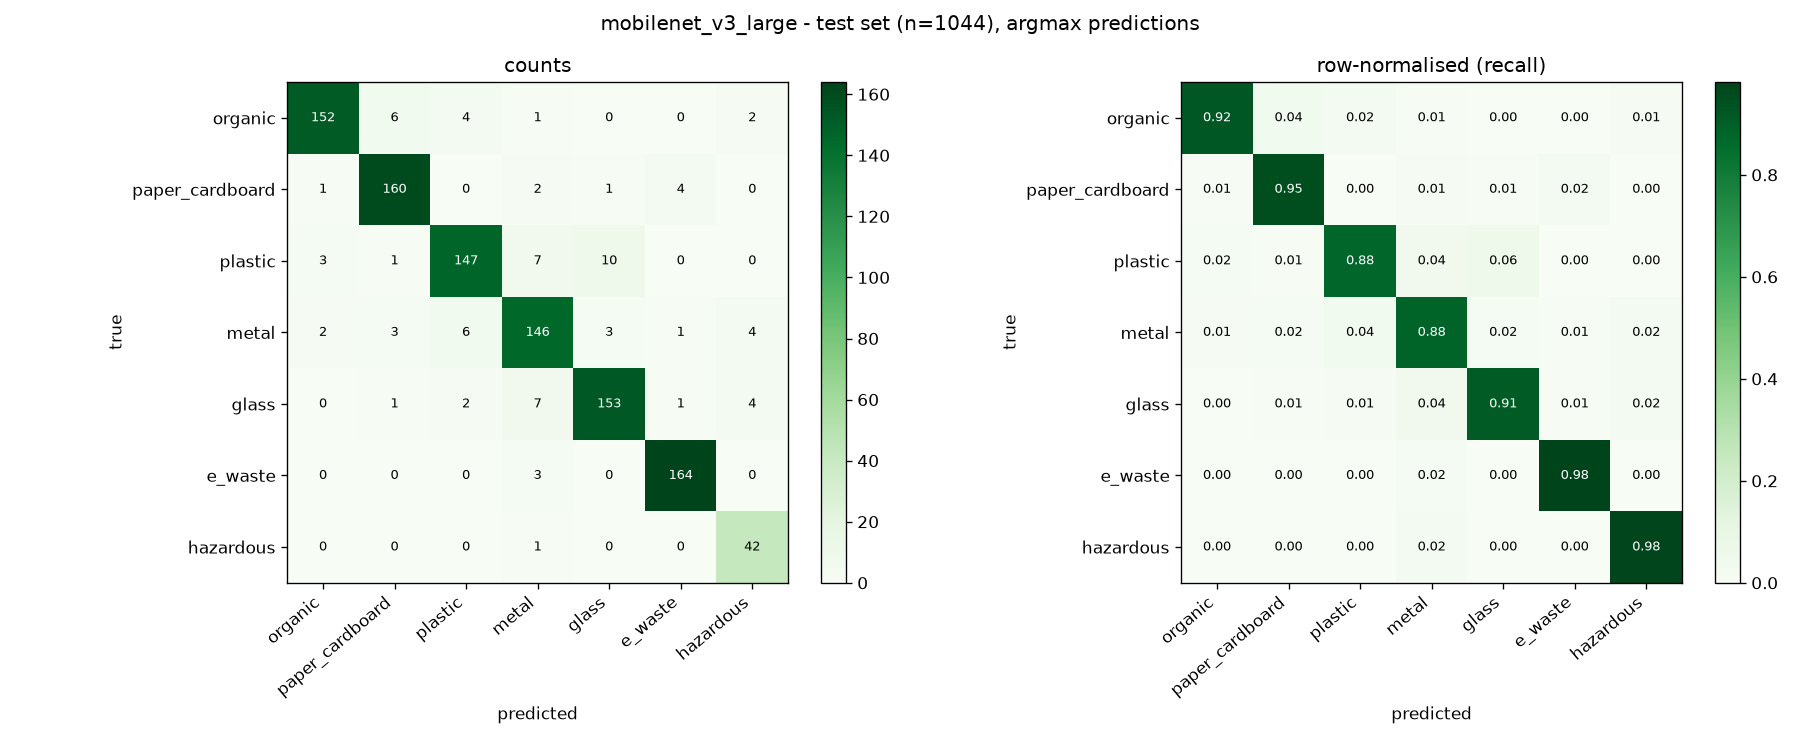

In [4]:
sel = json.load(open('ml/reports/model_comparison.json'))['selected']; print('selected:', sel)
Img(f'ml/reports/{sel}/confusion_matrix.png')

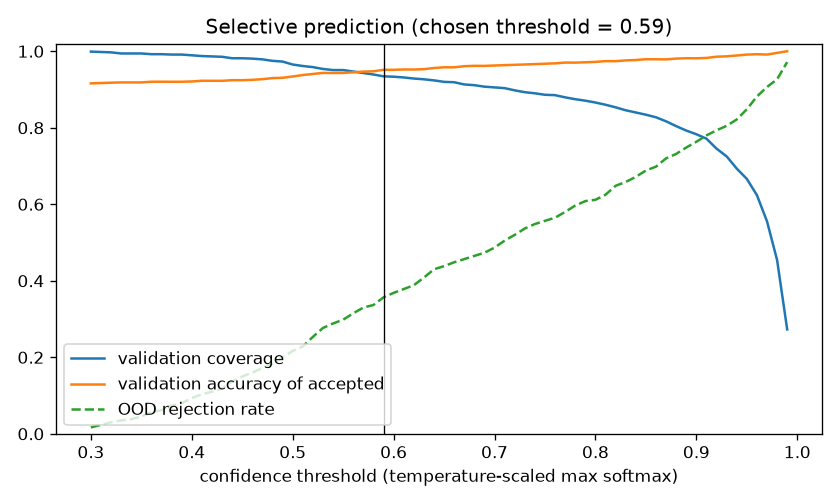

In [5]:
Img(f'ml/reports/{sel}/selective_curve.png')

In [6]:
e = evals[sel]
pd.Series({'temperature': e['temperature'], 'threshold': e['confidence_threshold'], **e['test_selective'],
           'ood_rejection_rate': e['ood']['rejection_rate']})

temperature             0.730708
threshold               0.590000
coverage                0.946360
accuracy_on_accepted    0.946356
accuracy_on_rejected    0.517857
ood_rejection_rate      0.356667
dtype: float64

### Safety-relevant classes and most frequent confusions

In [7]:
display(pd.DataFrame(e['safety_classes']).T)
pd.DataFrame(e['top_confusions'])

,recall,precision,support,missed_as,false_alarms_from
hazardous,0.976744,0.807692,43,{'metal': 1},"{'organic': 2, 'metal': 4, 'glass': 4}"
e_waste,0.982036,0.964706,167,{'metal': 3},"{'paper_cardboard': 4, 'metal': 1, 'glass': 1}"


,true,pred,count
0,plastic,glass,10
1,plastic,metal,7
2,glass,metal,7
3,organic,paper_cardboard,6
4,metal,plastic,6
5,organic,plastic,4
6,paper_cardboard,e_waste,4
7,metal,hazardous,4
8,glass,hazardous,4
9,plastic,organic,3


### Misclassified test images (safety-relevant errors first)

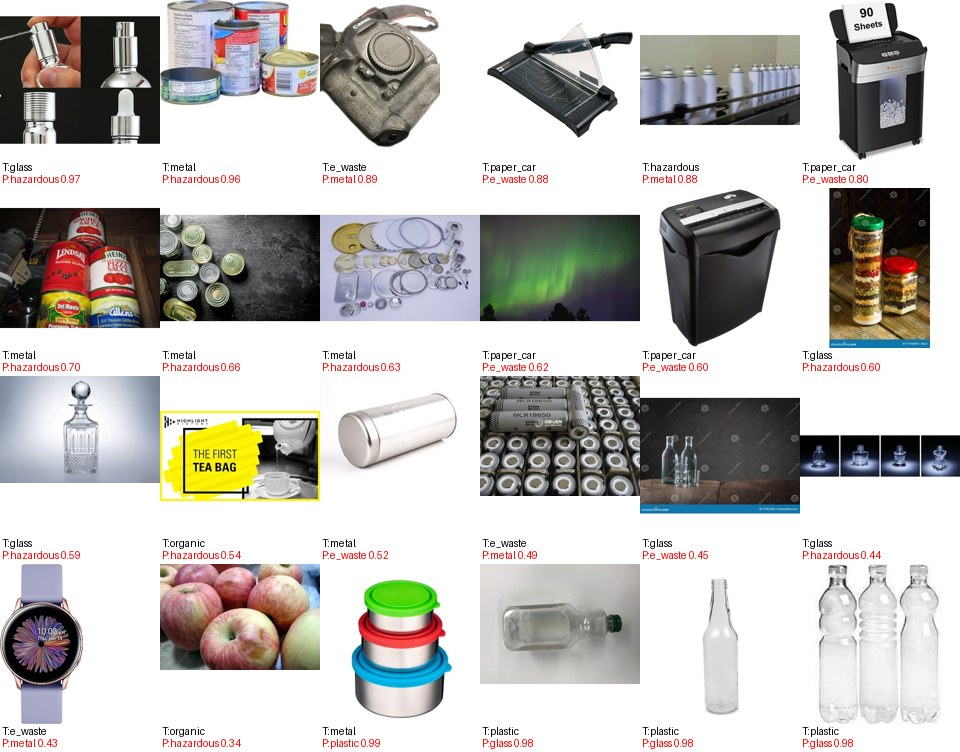

In [8]:
Img(f'ml/reports/{sel}/misclassified.jpg')